# Module 02 — Statistical Learning

**Applied exercises only** · ISLP, Chapter 2

**Printed textbook pages:** 65–67 (exercise starting pages)  

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# For datasets supplied by ISLP:
# from ISLP import load_data
# df = load_data('Auto')
rng = np.random.default_rng(1)

---

## Exercise 8 · Applied

**Textbook: printed page 65**

This exercise relates to the College data set, which can be found in
the file College.csv on the book website. It contains a number of
variables for 777 different universities and colleges in the US. The
variables are
• Private : Public/private indicator
• Apps : Number of applications received
• Accept : Number of applicants accepted
• Enroll : Number of new students enrolled
• Top10perc : New students from top 10 % of high school class
• Top25perc : New students from top 25 % of high school class
• F.Undergrad : Number of full-time undergraduates
• P.Undergrad : Number of part-time undergraduates
• Outstate : Out-of-state tuition
• Room.Board : Room and board costs
• Books : Estimated book costs
• Personal : Estimated personal spending
• PhD : Percent of faculty with Ph.D.s
• Terminal : Percent of faculty with terminal degree
• S.F.Ratio : Student/faculty ratio
• perc.alumni : Percent of alumni who donate
• Expend : Instructional expenditure per student
• Grad.Rate : Graduation rate
Before reading the data into Python, it can be viewed in Excel or a
text editor.

### Exercise 8(a)

Use the pd.read_csv() function to read the data into Python. Call
the loaded data college. Make sure that you have the directory
set to the correct location for the data.

In [2]:
# Exercise 8(a)
college = pd.read_csv("College.csv")
print(f"Loaded {college.shape[0]} colleges and {college.shape[1]} columns.")
display(college.head())

Loaded 777 colleges and 19 columns.


,Unnamed: 0,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
0,Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
1,Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
2,Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
3,Agnes Scott College,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
4,Alaska Pacific University,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


### Exercise 8(b)

Look at the data used in the notebook by creating and running
a new cell with just the code college in it. You should notice
that the first column is just the name of each university in a
column named something like Unnamed: 0. We don’t really want
pandas to treat this as data. However, it may be handy to have
these names for later. Try the following commands and similarly
look at the resulting data frames:
college2 = pd.read_csv('College.csv', index_col=0)
college3 = college.rename({'Unnamed: 0': 'College'},
axis=1)
college3 = college3.set_index('College')
This has used the first column in the file as an index for the
data frame. This means that pandas has given each row a name
corresponding to the appropriate university. Now you should see
that the first data column is Private. Note that the names of
the colleges appear on the left of the table. We also introduced
a new python object above: a dictionary, which is specified by dictionary
(key, value) pairs. Keep your modified version of the data with
the following:
college = college3

In [3]:
# Exercise 8(b)
college2 = pd.read_csv("College.csv", index_col=0)
college3 = college.rename({"Unnamed: 0": "College"}, axis=1).set_index("College")
assert college2.equals(college3)
college = college3
display(college.head())

,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
College,,,,,,,,,,,,,,,,,,
Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
Agnes Scott College,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
Alaska Pacific University,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


### Exercise 8(c)

Use the describe() method of to produce a numerical summary
of the variables in the data set.

In [4]:
# Exercise 8(c)
college.describe().round(2)

,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
count,777.00,777.00,777.00,777.00,777.0,777.00,777.00,777.00,777.00,777.00,777.00,777.00,777.00,777.00,777.00,777.00,777.00
mean,3001.64,2018.80,779.97,27.56,55.8,3699.91,855.30,10440.67,4357.53,549.38,1340.64,72.66,79.70,14.09,22.74,9660.17,65.46
std,3870.20,2451.11,929.18,17.64,19.8,4850.42,1522.43,4023.02,1096.70,165.11,677.07,16.33,14.72,3.96,12.39,5221.77,17.18
min,81.00,72.00,35.00,1.00,9.0,139.00,1.00,2340.00,1780.00,96.00,250.00,8.00,24.00,2.50,0.00,3186.00,10.00
25%,776.00,604.00,242.00,15.00,41.0,992.00,95.00,7320.00,3597.00,470.00,850.00,62.00,71.00,11.50,13.00,6751.00,53.00
50%,1558.00,1110.00,434.00,23.00,54.0,1707.00,353.00,9990.00,4200.00,500.00,1200.00,75.00,82.00,13.60,21.00,8377.00,65.00
75%,3624.00,2424.00,902.00,35.00,69.0,4005.00,967.00,12925.00,5050.00,600.00,1700.00,85.00,92.00,16.50,31.00,10830.00,78.00
max,48094.00,26330.00,6392.00,96.00,100.0,31643.00,21836.00,21700.00,8124.00,2340.00,6800.00,103.00,100.00,39.80,64.00,56233.00,118.00


### Exercise 8(d)

Use the pd.plotting.scatter_matrix() function to produce a
scatterplot matrix of the first columns [Top10perc, Apps, Enroll].
Recall that you can reference a list C of columns of a data frame
A using A[C].

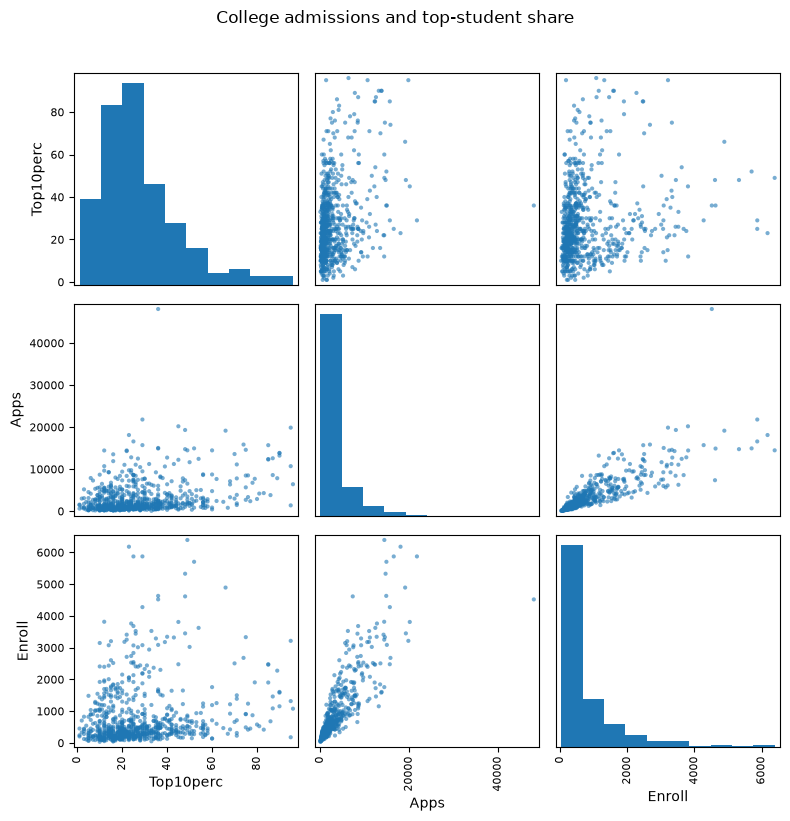

In [5]:
# Exercise 8(d)
scatter_columns = ["Top10perc", "Apps", "Enroll"]
axes = pd.plotting.scatter_matrix(
    college[scatter_columns], figsize=(8, 8), diagonal="hist", alpha=0.6
)
plt.suptitle("College admissions and top-student share", y=1.02)
plt.tight_layout()
plt.show()

### Exercise 8(e)

Use the boxplot() method of college to produce side-by-side
boxplots of Outstate versus Private.

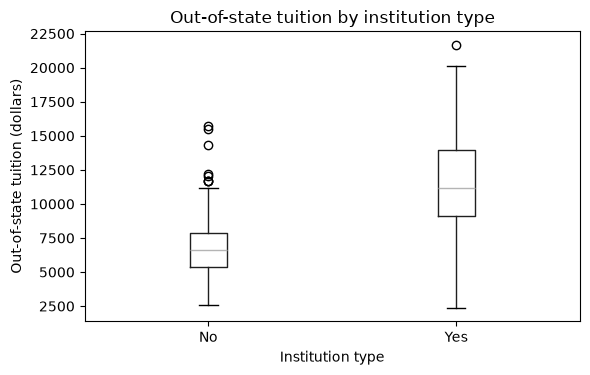

In [6]:
# Exercise 8(e)
ax = college.boxplot(column="Outstate", by="Private", figsize=(6, 4), grid=False)
ax.set_xlabel("Institution type")
ax.set_ylabel("Out-of-state tuition (dollars)")
ax.set_title("Out-of-state tuition by institution type")
plt.suptitle("")
plt.tight_layout()
plt.show()

### Exercise 8(f)

Create a new qualitative variable, called Elite, by binning the
Top10perc variable into two groups based on whether or not the
proportion of students coming from the top 10% of their high
school classes exceeds 50%.
college['Elite'] = pd.cut(college['Top10perc'],
[0,0.5,1],
labels=['No', 'Yes'])
Use the value_counts() method of college['Elite'] to see how
many elite universities there are. Finally, use the boxplot() method
again to produce side-by-side boxplots of Outstate versus Elite.

College counts by Elite status:
Elite
No     699
Yes     78
Name: count, dtype: int64


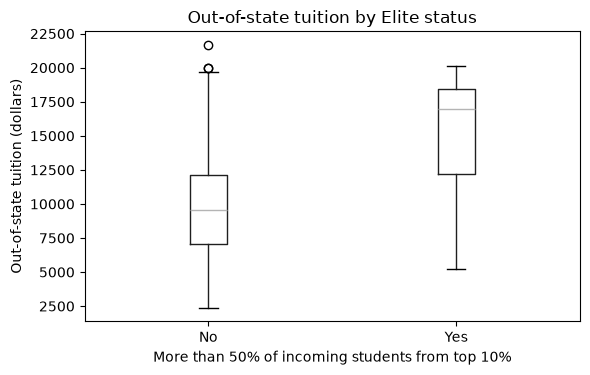

In [7]:
# Exercise 8(f)
# Top10perc is recorded on a 0–100 percentage scale, so the 50% cutoff is 50.
college["Elite"] = pd.cut(
    college["Top10perc"],
    bins=[0, 50, 100],
    labels=["No", "Yes"],
    include_lowest=True,
)
print("College counts by Elite status:")
print(college["Elite"].value_counts().sort_index())
ax = college.boxplot(column="Outstate", by="Elite", figsize=(6, 4), grid=False)
ax.set_xlabel("More than 50% of incoming students from top 10%")
ax.set_ylabel("Out-of-state tuition (dollars)")
ax.set_title("Out-of-state tuition by Elite status")
plt.suptitle("")
plt.tight_layout()
plt.show()

### Exercise 8(g)

Use the plot.hist() method of college to produce some histograms with differing numbers of bins for a few of the quantitative variables. The command plt.subplots(2, 2) may be useful: it will divide the plot window into four regions so that four
plots can be made simultaneously. By changing the arguments
you can divide the screen up in other combinations.

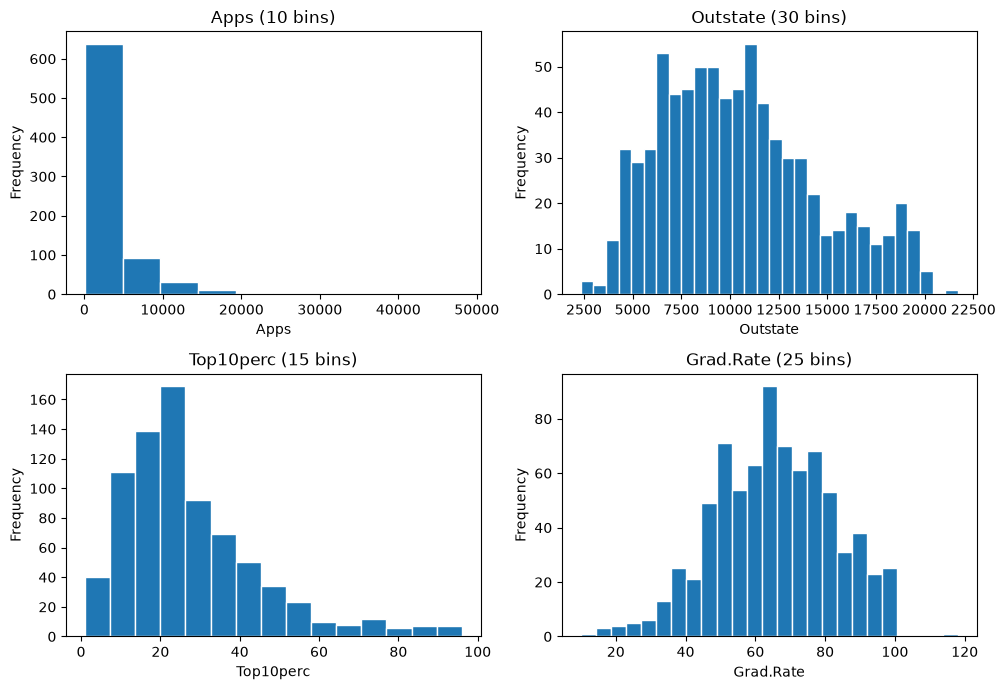

In [8]:
# Exercise 8(g)
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, variable, bins in zip(
    axes.flat,
    ["Apps", "Outstate", "Top10perc", "Grad.Rate"],
    [10, 30, 15, 25],
):
    college[variable].plot.hist(bins=bins, ax=ax, edgecolor="white")
    ax.set_title(f"{variable} ({bins} bins)")
    ax.set_xlabel(variable)
plt.tight_layout()
plt.show()

### Exercise 8(h)

Continue exploring the data, and provide a brief summary of
what you discover.

In [9]:
# Exercise 8(h)
print("Out-of-state tuition by institution type:")
print(college.groupby("Private", observed=True)["Outstate"].agg(["median", "mean"]).round(1))
print("\nCorrelations among selected numeric variables:")
print(college[["Apps", "Enroll", "Outstate", "Top10perc", "Grad.Rate"]].corr().round(2))
print("\nColleges reporting graduation rates above 100%:")
display(college.loc[college["Grad.Rate"] > 100, ["Grad.Rate", "Private", "Outstate"]])

Out-of-state tuition by institution type:
          median     mean
Private                  
No        6609.0   6813.4
Yes      11200.0  11801.7

Correlations among selected numeric variables:
           Apps  Enroll  Outstate  Top10perc  Grad.Rate
Apps       1.00    0.85      0.05       0.34       0.15
Enroll     0.85    1.00     -0.16       0.18      -0.02
Outstate   0.05   -0.16      1.00       0.56       0.57
Top10perc  0.34    0.18      0.56       1.00       0.49
Grad.Rate  0.15   -0.02      0.57       0.49       1.00

Colleges reporting graduation rates above 100%:


,Grad.Rate,Private,Outstate
College,,,
Cazenovia College,118,Yes,9384



**Summary.** Applications and enrollment are strongly right-skewed, and colleges with more applications generally enroll more students. Private colleges have higher out-of-state tuition in this sample (median \$11,200 versus \$6,609 at public colleges). The 78 schools classified as Elite by the $>50\%$ Top10perc cutoff also tend to have higher tuition. Tuition is moderately positively associated with Top10perc and graduation rate. One data-quality oddity is Cazenovia College's reported graduation rate of 118%, so that value should be treated cautiously.


---

## Exercise 9 · Applied

**Textbook: printed page 66**

This exercise involves the Auto data set studied in the lab. Make sure
that the missing values have been removed from the data.

### Exercise 9(a)

Which of the predictors are quantitative, and which are qualitative?

In [10]:
# Exercise 9(a)
auto = pd.read_csv("Auto.csv", na_values="?").dropna().reset_index(drop=True)
print(f"After removing missing rows: {len(auto)} observations, {auto.shape[1]} variables.")
quantitative_auto = [
    "mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "year"
]
qualitative_auto = ["origin", "name"]
print("Quantitative:", quantitative_auto)
print("Qualitative:", qualitative_auto)

After removing missing rows: 392 observations, 9 variables.
Quantitative: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'year']
Qualitative: ['origin', 'name']


### Exercise 9(b)

What is the range of each quantitative predictor? You can answer this using the min() and max() methods in numpy.
.min()
.max()

In [11]:
# Exercise 9(b)
auto_ranges = pd.DataFrame({"minimum": auto[quantitative_auto].min(), "maximum": auto[quantitative_auto].max()})
auto_ranges["range"] = auto_ranges["maximum"] - auto_ranges["minimum"]
auto_ranges

,minimum,maximum,range
mpg,9.0,46.6,37.6
cylinders,3.0,8.0,5.0
displacement,68.0,455.0,387.0
horsepower,46.0,230.0,184.0
weight,1613.0,5140.0,3527.0
acceleration,8.0,24.8,16.8
year,70.0,82.0,12.0


### Exercise 9(c)

What is the mean and standard deviation of each quantitative
predictor?

In [12]:
# Exercise 9(c)
auto[quantitative_auto].agg(["mean", "std"]).T.round(3)

,mean,std
mpg,23.446,7.805
cylinders,5.472,1.706
displacement,194.412,104.644
horsepower,104.469,38.491
weight,2977.584,849.403
acceleration,15.541,2.759
year,75.980,3.684


### Exercise 9(d)

Now remove the 10th through 85th observations. What is the
range, mean, and standard deviation of each predictor in the
subset of the data that remains?

In [13]:
# Exercise 9(d)
auto_remainder = pd.concat([auto.iloc[:9], auto.iloc[85:]], ignore_index=True)
remaining_summary = auto_remainder[quantitative_auto].agg(["min", "max", "mean", "std"]).T
remaining_summary["range"] = remaining_summary["max"] - remaining_summary["min"]
print(f"Removed rows 10 through 85; retained {len(auto_remainder)} of {len(auto)} cars.")
remaining_summary[["min", "max", "range", "mean", "std"]].round(3)

Removed rows 10 through 85; retained 316 of 392 cars.


,min,max,range,mean,std
mpg,11.0,46.6,35.6,24.404,7.867
cylinders,3.0,8.0,5.0,5.373,1.654
displacement,68.0,455.0,387.0,187.241,99.678
horsepower,46.0,230.0,184.0,100.722,35.709
weight,1649.0,4997.0,3348.0,2935.972,811.300
acceleration,8.5,24.8,16.3,15.727,2.694
year,70.0,82.0,12.0,77.146,3.106


### Exercise 9(e)

Using the full data set, investigate the predictors graphically,
using scatterplots or other tools of your choice. Create some plots
highlighting the relationships among the predictors. Comment
on your findings.

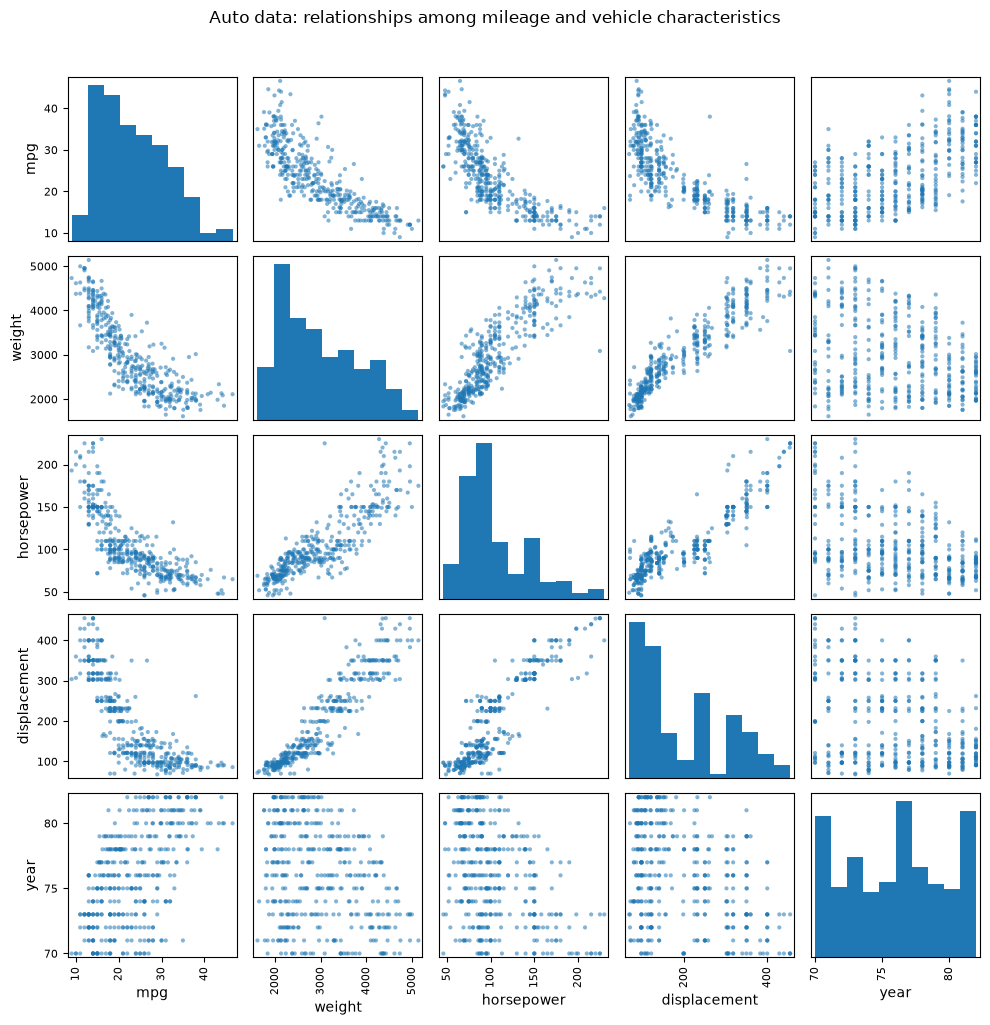

Selected correlations with mpg:
mpg             1.000
year            0.581
horsepower     -0.778
displacement   -0.805
weight         -0.832
Name: mpg, dtype: float64


In [14]:
# Exercise 9(e)
plot_columns = ["mpg", "weight", "horsepower", "displacement", "year"]
axes = pd.plotting.scatter_matrix(
    auto[plot_columns], figsize=(10, 10), diagonal="hist", alpha=0.55
)
plt.suptitle("Auto data: relationships among mileage and vehicle characteristics", y=1.02)
plt.tight_layout()
plt.show()
print("Selected correlations with mpg:")
print(auto[plot_columns].corr()["mpg"].sort_values(ascending=False).round(3))

### Exercise 9(f)

Suppose that we wish to predict gas mileage (mpg) on the basis
of the other variables. Do your plots suggest that any of the
other variables might be useful in predicting mpg? Justify your
answer.

In [15]:
# Exercise 9(f)
mpg_correlations = auto.drop(columns=["name", "origin"]).corr()["mpg"].drop("mpg").sort_values()
display(mpg_correlations.to_frame("correlation with mpg").round(3))
print(
    "Weight, displacement, horsepower, and cylinders are promising predictors: "
    "their associations with mpg are strong and negative. Model year is also useful "
    "because newer cars tend to achieve higher mpg. These are associations, not "
    "causal effects, and the predictors are themselves correlated."
)

,correlation with mpg
weight,-0.832
displacement,-0.805
horsepower,-0.778
cylinders,-0.778
acceleration,0.423
year,0.581


Weight, displacement, horsepower, and cylinders are promising predictors: their associations with mpg are strong and negative. Model year is also useful because newer cars tend to achieve higher mpg. These are associations, not causal effects, and the predictors are themselves correlated.


**Summary.** After removing missing horsepower values, 392 cars remain. Quantitative variables are mpg, cylinders, displacement, horsepower, weight, acceleration, and model year; origin is a coded category and name is a label. The scatterplots show mpg decreasing as weight, displacement, and horsepower increase, while newer model years tend to have higher mpg. Weight, displacement, horsepower, cylinders, and year therefore look useful for predicting mpg, although several predictors are correlated and plots alone do not establish causation.

---

## Exercise 10 · Applied

**Textbook: printed page 67**

This exercise involves the Boston housing data set.

### Exercise 10(a)

To begin, load in the Boston data set, which is part of the ISLP
library.

In [16]:
# Exercise 10(a)
# Use the chapter's local copy so this notebook does not depend on a network download.
boston = pd.read_csv("Boston.csv", index_col=0)
print(f"Boston data shape: {boston.shape}")
print("Columns:", list(boston.columns))
display(boston.head())

Boston data shape: (506, 13)
Columns: ['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'lstat', 'medv']


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


### Exercise 10(b)

How many rows are in this data set? How many columns? What
do the rows and columns represent?

In [17]:
# Exercise 10(b)
print(f"Rows: {boston.shape[0]} census-tract observations")
print(f"Columns: {boston.shape[1]} variables")
print(
    "Each row describes a Boston-area census tract (called a suburb in the "
    "textbook); the columns record tract-level housing, socioeconomic, "
    "environmental, and geographic measurements."
)

Rows: 506 census-tract observations
Columns: 13 variables
Each row describes a Boston-area census tract (called a suburb in the textbook); the columns record tract-level housing, socioeconomic, environmental, and geographic measurements.


### Exercise 10(c)

Make some pairwise scatterplots of the predictors (columns) in
this data set. Describe your findings.

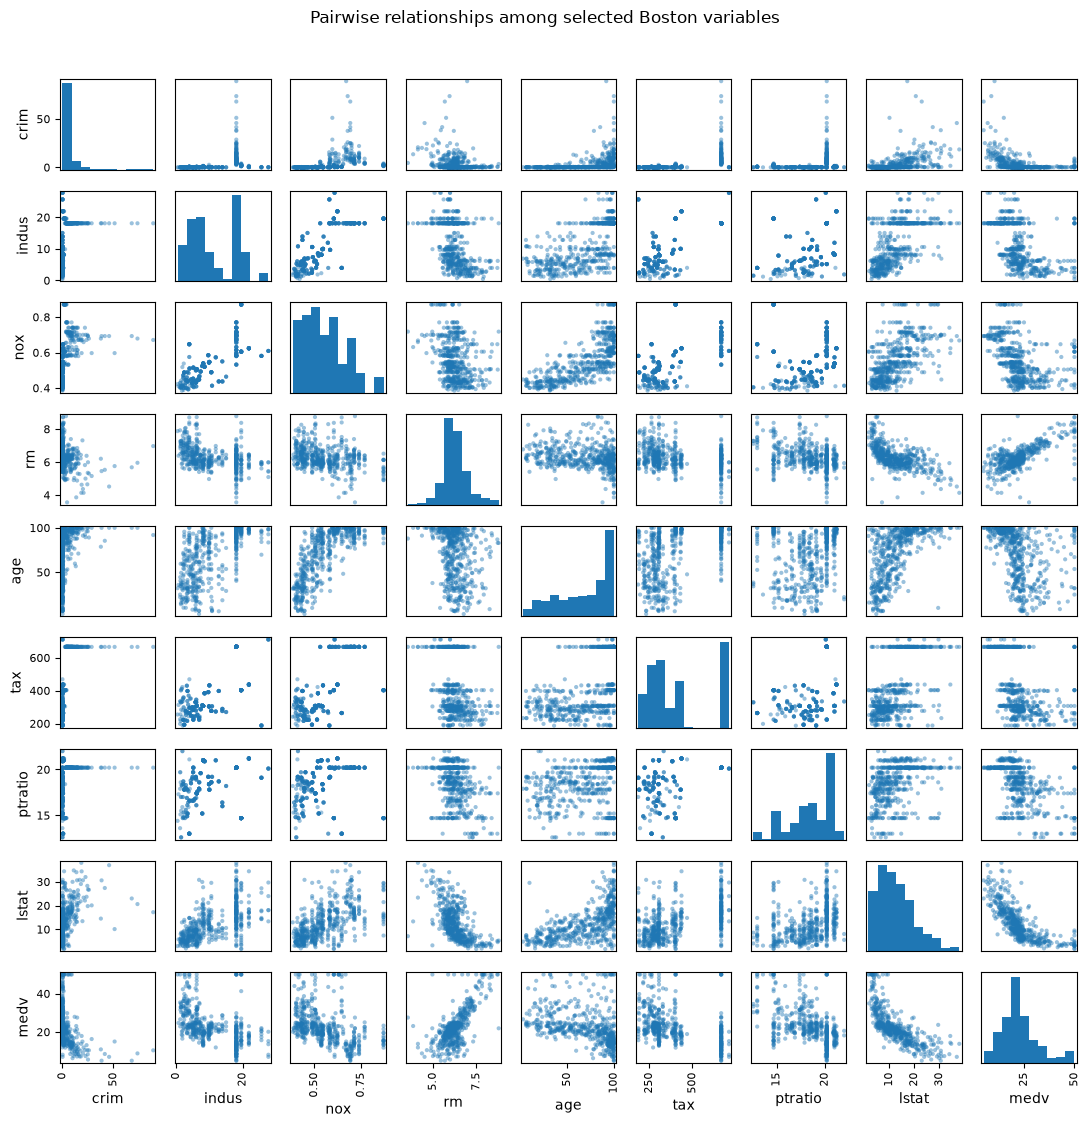

Selected correlations with medv:
lstat     -0.74
ptratio   -0.51
indus     -0.48
tax       -0.47
nox       -0.43
crim      -0.39
age       -0.38
rm         0.70
medv       1.00
Name: medv, dtype: float64


In [18]:
# Exercise 10(c)
plot_columns_boston = ["crim", "indus", "nox", "rm", "age", "tax", "ptratio", "lstat", "medv"]
pd.plotting.scatter_matrix(
    boston[plot_columns_boston], figsize=(11, 11), diagonal="hist", alpha=0.45
)
plt.suptitle("Pairwise relationships among selected Boston variables", y=1.02)
plt.tight_layout()
plt.show()
print("Selected correlations with medv:")
print(boston[plot_columns_boston].corr()["medv"].sort_values().round(2))

### Exercise 10(d)

Are any of the predictors associated with per capita crime rate?
If so, explain the relationship.

,correlation with crim
medv,-0.388
dis,-0.380
rm,-0.219
zn,-0.200
chas,-0.056
ptratio,0.290
age,0.353
indus,0.407
nox,0.421
lstat,0.456


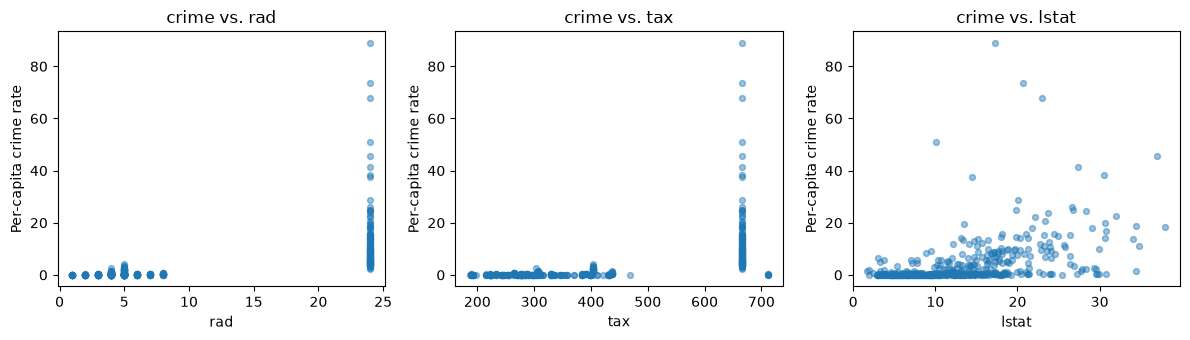

In [19]:
# Exercise 10(d)
crime_correlations = boston.corr(numeric_only=True)["crim"].drop("crim").sort_values()
display(crime_correlations.to_frame("correlation with crim").round(3))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, variable in zip(axes, ["rad", "tax", "lstat"]):
    ax.scatter(boston[variable], boston["crim"], alpha=0.45, s=18)
    ax.set_xlabel(variable)
    ax.set_ylabel("Per-capita crime rate")
    ax.set_title(f"crime vs. {variable}")
plt.tight_layout()
plt.show()

### Exercise 10(e)

Do any of the suburbs of Boston appear to have particularly
high crime rates? Tax rates? Pupil-teacher ratios? Comment on
the range of each predictor.

In [20]:
# Exercise 10(e)
key_columns = ["crim", "tax", "ptratio"]
print("Overall predictor ranges:")
display(pd.DataFrame({"min": boston.min(), "max": boston.max(), "range": boston.max() - boston.min()}).round(3))
for variable in key_columns:
    print(f"\nHighest values of {variable}:")
    display(boston.nlargest(5, variable)[[variable, "rad", "tax", "ptratio", "medv"]])

Overall predictor ranges:


,min,max,range
crim,0.006,88.976,88.970
zn,0.000,100.000,100.000
indus,0.460,27.740,27.280
chas,0.000,1.000,1.000
nox,0.385,0.871,0.486
rm,3.561,8.780,5.219
age,2.900,100.000,97.100
dis,1.130,12.126,10.997
rad,1.000,24.000,23.000
tax,187.000,711.000,524.000



Highest values of crim:


,crim,rad,tax,ptratio,medv
381,88.9762,24,666,20.2,10.4
419,73.5341,24,666,20.2,8.8
406,67.9208,24,666,20.2,5.0
411,51.1358,24,666,20.2,15.0
415,45.7461,24,666,20.2,7.0



Highest values of tax:


,tax,rad,tax,ptratio,medv
489,711,4,711,20.1,15.2
490,711,4,711,20.1,7.0
491,711,4,711,20.1,8.1
492,711,4,711,20.1,13.6
493,711,4,711,20.1,20.1



Highest values of ptratio:


,ptratio,rad,tax,ptratio,medv
355,22.0,4,334,22.0,18.2
356,22.0,4,334,22.0,20.6
128,21.2,4,437,21.2,16.2
129,21.2,4,437,21.2,18.0
130,21.2,4,437,21.2,14.3


### Exercise 10(f)

How many of the suburbs in this data set bound the Charles
river?

In [21]:
# Exercise 10(f)
charles_count = int((boston["chas"] == 1).sum())
print(f"{charles_count} of {len(boston)} tracts bound the Charles River.")

35 of 506 tracts bound the Charles River.


### Exercise 10(g)

What is the median pupil-teacher ratio among the towns in this
data set?

In [22]:
# Exercise 10(g)
median_ptratio = boston["ptratio"].median()
print(f"Median pupil-teacher ratio: {median_ptratio:.1f} to 1")

Median pupil-teacher ratio: 19.1 to 1


### Exercise 10(h)

Which suburb of Boston has lowest median value of owneroccupied homes? What are the values of the other predictors
for that suburb, and how do those values compare to the overall
ranges for those predictors? Comment on your findings.

In [23]:
# Exercise 10(h)
minimum_medv = boston["medv"].min()
lowest_value_tracts = boston.loc[boston["medv"] == minimum_medv].copy()
print(f"Minimum median home value: ${minimum_medv:.1f} thousand; {len(lowest_value_tracts)} tracts share this minimum.")
display(lowest_value_tracts.T.rename(columns=lambda index: f"tract {index}"))
print("\nFor comparison, each tract's values against the dataset ranges:")
range_comparison = pd.DataFrame(
    {
        "tract_value": lowest_value_tracts.mean(),
        "minimum": boston.min(),
        "maximum": boston.max(),
        "overall_median": boston.median(),
    }
)
range_comparison.round(3)

Minimum median home value: $5.0 thousand; 2 tracts share this minimum.


,tract 399,tract 406
crim,38.3518,67.9208
zn,0.0000,0.0000
indus,18.1000,18.1000
chas,0.0000,0.0000
nox,0.6930,0.6930
rm,5.4530,5.6830
age,100.0000,100.0000
dis,1.4896,1.4254
rad,24.0000,24.0000
tax,666.0000,666.0000



For comparison, each tract's values against the dataset ranges:


,tract_value,minimum,maximum,overall_median
crim,53.136,0.006,88.976,0.257
zn,0.000,0.000,100.000,0.000
indus,18.100,0.460,27.740,9.690
chas,0.000,0.000,1.000,0.000
nox,0.693,0.385,0.871,0.538
rm,5.568,3.561,8.780,6.208
age,100.000,2.900,100.000,77.500
dis,1.458,1.130,12.126,3.207
rad,24.000,1.000,24.000,5.000
tax,666.000,187.000,711.000,330.000


### Exercise 10(i)

In this data set, how many of the suburbs average more than
seven rooms per dwelling? More than eight rooms per dwelling?
Comment on the suburbs that average more than eight rooms
per dwelling.

In [24]:
# Exercise 10(i)
more_than_seven = boston.loc[boston["rm"] > 7]
more_than_eight = boston.loc[boston["rm"] > 8]
print(f"Tracts averaging more than 7 rooms: {len(more_than_seven)}")
print(f"Tracts averaging more than 8 rooms: {len(more_than_eight)}")
print("\nSummary of tracts with more than 8 rooms:")
display(more_than_eight[["rm", "crim", "ptratio", "lstat", "medv"]].describe().round(2))
print("\nTracts with more than 8 rooms:")
display(more_than_eight[["rm", "crim", "ptratio", "lstat", "medv"]].sort_values("rm", ascending=False))

Tracts averaging more than 7 rooms: 64
Tracts averaging more than 8 rooms: 13

Summary of tracts with more than 8 rooms:


,rm,crim,ptratio,lstat,medv
count,13.00,13.00,13.00,13.00,13.00
mean,8.35,0.72,16.36,4.31,44.20
std,0.25,0.90,2.41,1.37,8.09
min,8.03,0.02,13.00,2.47,21.90
25%,8.25,0.33,14.70,3.32,41.70
50%,8.30,0.52,17.40,4.14,48.30
75%,8.40,0.58,17.40,5.12,50.00
max,8.78,3.47,20.20,7.44,50.00



Tracts with more than 8 rooms:


,rm,crim,ptratio,lstat,medv
365,8.780,3.47428,20.2,5.29,21.9
226,8.725,0.52693,17.4,4.63,50.0
258,8.704,0.61154,13.0,5.12,50.0
263,8.398,0.52014,13.0,5.91,48.8
164,8.375,1.51902,14.7,3.32,50.0
233,8.337,0.57529,17.4,2.47,41.7
268,8.297,0.57834,13.0,7.44,50.0
225,8.266,0.31533,17.4,4.14,44.8
254,8.259,0.36894,19.1,3.54,42.8
234,8.247,0.33147,17.4,3.95,48.3



**Summary.** The Boston file contains 506 census tracts and 13 variables. Crime is strongly right-skewed, with a maximum of 88.98; it is positively associated with highway accessibility (`rad`, $r\approx0.626$), property-tax rate (`tax`, $r\approx0.583$), and lower-status population share (`lstat`, $r\approx0.456$). The ranges differ greatly because the predictors use different units. Thirty-five tracts border the Charles River, and the median pupil-teacher ratio is 19.1.

Two tracts tie for the lowest median home value, \$5,000 (the response is in thousands of dollars); both have very high crime, older housing, and high highway-accessibility indices. Sixty-four tracts average more than seven rooms and 13 average more than eight. Those 13 generally have low `lstat` and high home values, although the response is capped at \$50,000 and one tract is an exception with a value of \$21,900.
